# SentimentForge — RNN & LSTM Models

This notebook implements sequence-based deep learning models
for IMDb movie review sentiment classification using PyTorch.

Objectives:
- Recreate tokenized and padded sequences
- Understand word embeddings
- Implement a basic RNN
- Implement an LSTM
- Train and evaluate both models

In [ ]:
import os
import json
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

PyTorch version: 2.11.0+cu130
CUDA available: True
Device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/SentimentForge"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
DATA_DIR = os.path.join(PROJECT_DIR, "data")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")

DATASET_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "raw",
    "IMDB Dataset.csv"
)

TOKENIZER_PATH = os.path.join(MODEL_DIR, "tokenizer.pkl")
CONFIG_PATH = os.path.join(MODEL_DIR, "preprocessing_config.json")

device = torch.device("cuda")

print("Project directory:", PROJECT_DIR)
print("Model directory exists:", os.path.exists(MODEL_DIR))
print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Tokenizer exists:", os.path.exists(TOKENIZER_PATH))
print("Config exists:", os.path.exists(CONFIG_PATH))
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/SentimentForge
Model directory exists: True
Dataset exists: True
Tokenizer exists: True
Config exists: True
GPU: Tesla T4


In [ ]:
df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing values:
review       0
sentiment    0
dtype: int64


In [ ]:
# Load tokenizer
with open(TOKENIZER_PATH, "rb") as f:
    tokenizer = pickle.load(f)

# Load preprocessing configuration
with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

print("Tokenizer loaded successfully!")
print("\nPreprocessing configuration:")

for key, value in config.items():
    print(f"{key}: {value}")

print("\nVocabulary size:", len(tokenizer.word_index))
print("OOV token:", tokenizer.oov_token)
print("PAD token ID:", 0)

Tokenizer loaded successfully!

Preprocessing configuration:
max_words: 30000
max_length: 300
padding: post
truncating: post
oov_token: <OOV>
negative_label: 0
positive_label: 1

Vocabulary size: 107696
OOV token: <OOV>
PAD token ID: 0


In [ ]:
import re
from bs4 import BeautifulSoup

def clean_review(text):
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
df["clean_review"] = df["review"].apply(clean_review)

label_map = {
    "negative": 0,
    "positive": 1
}

df["label"] = df["sentiment"].map(label_map)

print(df[["clean_review", "label"]].head())
print("\nLabel distribution:")
print(df["label"].value_counts())

                                        clean_review  label
0  one of the other reviewers has mentioned that ...      1
1  a wonderful little production the filming tech...      1
2  i thought this was a wonderful way to spend ti...      1
3  basically there's a family where a little boy ...      0
4  petter mattei's love in the time of money is a...      1

Label distribution:
label
1    25000
0    25000
Name: count, dtype: int64


In [ ]:
X = df["clean_review"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (40000,)
Validation: (5000,)
Test: (5000,)


In [ ]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training: (40000,) (40000,)
Validation: (5000,) (5000,)
Testing: (5000,) (5000,)

Training labels:
label
1    20000
0    20000
Name: count, dtype: int64

Validation labels:
label
0    2500
1    2500
Name: count, dtype: int64

Testing labels:
label
0    2500
1    2500
Name: count, dtype: int64


In [ ]:
MAX_WORDS = config["max_words"]
MAX_LEN = config["max_length"]

# Convert text into integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("First review tokens:", X_train_seq[0][:20])
print("First review sequence length:", len(X_train_seq[0]))

First review tokens: [10, 1044, 11, 119, 1499, 454, 31, 1594, 142, 8, 38, 426, 10, 13, 30, 4, 8587, 1658, 6, 63]
First review sequence length: 163


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Sequence length:", X_train_pad.shape[1])
print("First sequence:", X_train_pad[0][:30])

pad_count = np.sum(X_train_pad[0] == 0)

print("Padding tokens in first review:", pad_count)
print("Actual tokens retained:", np.sum(X_train_pad[0] != 0))

Training shape: (40000, 300)
Validation shape: (5000, 300)
Testing shape: (5000, 300)
Sequence length: 300
First sequence: [  10 1044   11  119 1499  454   31 1594  142    8   38  426   10   13
   30    4 8587 1658    6   63  105  157  666  862  860   97    2 1658
   13 2809]
Padding tokens in first review: 137
Actual tokens retained: 163


In [ ]:
# Convert input sequences to integer tensors
X_train_tensor = torch.tensor(X_train_pad, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_pad, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_pad, dtype=torch.long)

# Convert labels to float tensors
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

print("Training tensor:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)

print("\nInput dtype:", X_train_tensor.dtype)
print("Label dtype:", y_train_tensor.dtype)

Training tensor: torch.Size([40000, 300])
Training labels: torch.Size([40000])

Input dtype: torch.int64
Label dtype: torch.float32


In [ ]:
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 625
Validation batches: 79
Testing batches: 79


In [ ]:
sample_X, sample_y = next(iter(train_loader))

print("Batch input shape:", sample_X.shape)
print("Batch label shape:", sample_y.shape)
print("Input dtype:", sample_X.dtype)
print("Label dtype:", sample_y.dtype)

Batch input shape: torch.Size([64, 300])
Batch label shape: torch.Size([64])
Input dtype: torch.int64
Label dtype: torch.float32


In [ ]:
class SimpleRNN(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(SimpleRNN, self).__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        embedded = self.embedding(x)

        output, hidden = self.rnn(embedded)

        last_hidden = hidden[-1]

        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)

In [ ]:
VOCAB_SIZE = MAX_WORDS
EMBEDDING_DIM = 128
HIDDEN_DIM = 128

rnn_model = SimpleRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
)

rnn_model = rnn_model.to(device)

print(rnn_model)

SimpleRNN(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [ ]:
total_params = sum(
    p.numel() for p in rnn_model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

print("\nEmbedding weights:", rnn_model.embedding.weight.shape)
print("RNN input weights:", rnn_model.rnn.weight_ih_l0.shape)
print("RNN hidden weights:", rnn_model.rnn.weight_hh_l0.shape)
print("Output weights:", rnn_model.fc.weight.shape)

Total trainable parameters: 3873153

Embedding weights: torch.Size([30000, 128])
RNN input weights: torch.Size([128, 128])
RNN hidden weights: torch.Size([128, 128])
Output weights: torch.Size([1, 128])


In [ ]:
# Get one batch
sample_X, sample_y = next(iter(train_loader))

# Move batch to GPU
sample_X = sample_X.to(device)

# Evaluation mode
rnn_model.eval()

# Disable gradient calculation
with torch.no_grad():
    sample_output = rnn_model(sample_X)

print("Input shape:", sample_X.shape)
print("Output shape:", sample_output.shape)
print("Sample logits:", sample_output[:5])

Input shape: torch.Size([64, 300])
Output shape: torch.Size([64])
Sample logits: tensor([-0.2082,  0.0434,  0.0434,  0.0434,  0.1756], device='cuda:0')


In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    rnn_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(inputs)

        loss = criterion(logits, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).int()

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy

In [ ]:
def evaluate_model(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            logits = model(inputs)

            loss = criterion(logits, labels)

            total_loss += loss.item()

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).int()

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probabilities.cpu().numpy())

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    }

In [ ]:
EPOCHS = 5

rnn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        rnn_model, train_loader, criterion, optimizer, device
    )

    val_metrics = evaluate_model(
        rnn_model, val_loader, criterion, device
    )

    rnn_history["train_loss"].append(train_loss)
    rnn_history["train_accuracy"].append(train_acc)
    rnn_history["val_loss"].append(val_metrics["loss"])
    rnn_history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6955 | Train Acc: 0.4988 | Val Loss: 0.6920 | Val Acc: 0.5184
Epoch 2/5 | Train Loss: 0.6902 | Train Acc: 0.5169 | Val Loss: 0.6940 | Val Acc: 0.5142
Epoch 3/5 | Train Loss: 0.6927 | Train Acc: 0.5188 | Val Loss: 0.6945 | Val Acc: 0.5058
Epoch 4/5 | Train Loss: 0.6864 | Train Acc: 0.5283 | Val Loss: 0.6979 | Val Acc: 0.5112
Epoch 5/5 | Train Loss: 0.6764 | Train Acc: 0.5383 | Val Loss: 0.6991 | Val Acc: 0.5064


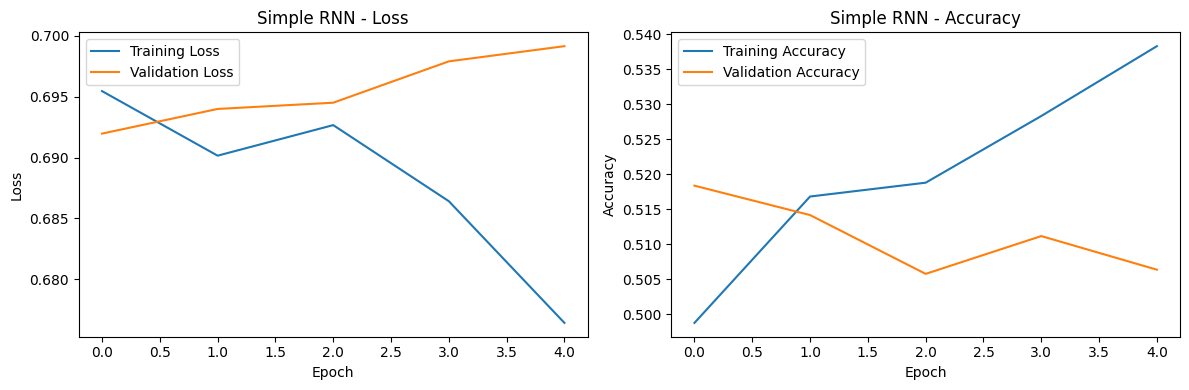

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(rnn_history["train_loss"], label="Training Loss")
plt.plot(rnn_history["val_loss"], label="Validation Loss")
plt.title("Simple RNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rnn_history["train_accuracy"], label="Training Accuracy")
plt.plot(rnn_history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
class LSTMModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        last_hidden = hidden[-1]

        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)

In [ ]:
lstm_model = LSTMModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
)

lstm_model = lstm_model.to(device)

print(lstm_model)

total_params = sum(
    p.numel() for p in lstm_model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

LSTMModel(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Total trainable parameters: 3972225


In [ ]:
sample_X, sample_y = next(iter(train_loader))
sample_X = sample_X.to(device)

lstm_model.eval()

with torch.no_grad():
    lstm_output = lstm_model(sample_X)

print("Input shape:", sample_X.shape)
print("Output shape:", lstm_output.shape)
print("Sample logits:", lstm_output[:5])

Input shape: torch.Size([64, 300])
Output shape: torch.Size([64])
Sample logits: tensor([0.0501, 0.0501, 0.0315, 0.0828, 0.0501], device='cuda:0')


In [ ]:
lstm_criterion = nn.BCEWithLogitsLoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("Loss:", lstm_criterion)
print("Optimizer:", lstm_optimizer)

Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
EPOCHS = 5

lstm_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        lstm_model,
        train_loader,
        lstm_criterion,
        lstm_optimizer,
        device
    )

    val_metrics = evaluate_model(
        lstm_model,
        val_loader,
        lstm_criterion,
        device
    )

    lstm_history["train_loss"].append(train_loss)
    lstm_history["train_accuracy"].append(train_acc)
    lstm_history["val_loss"].append(val_metrics["loss"])
    lstm_history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6942 | Train Acc: 0.5049 | Val Loss: 0.6932 | Val Acc: 0.5038
Epoch 2/5 | Train Loss: 0.6924 | Train Acc: 0.5143 | Val Loss: 0.6913 | Val Acc: 0.5090
Epoch 3/5 | Train Loss: 0.6861 | Train Acc: 0.5361 | Val Loss: 0.6904 | Val Acc: 0.5230
Epoch 4/5 | Train Loss: 0.6416 | Train Acc: 0.6377 | Val Loss: 0.6872 | Val Acc: 0.5354
Epoch 5/5 | Train Loss: 0.5853 | Train Acc: 0.7088 | Val Loss: 0.6097 | Val Acc: 0.7206


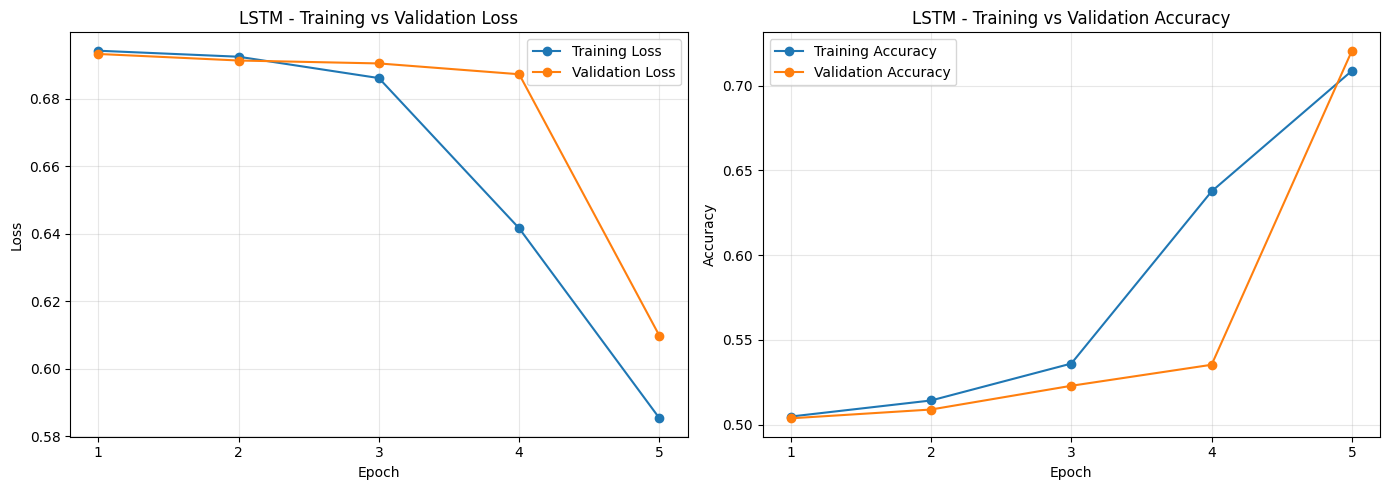

In [ ]:
plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(
    range(1, EPOCHS + 1),
    lstm_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    lstm_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("LSTM - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)


# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    range(1, EPOCHS + 1),
    lstm_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    lstm_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("LSTM - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame([
    {
        "Model": "Simple RNN",
        "Train Accuracy": rnn_history["train_accuracy"][-1],
        "Validation Accuracy": rnn_history["val_accuracy"][-1],
        "Train Loss": rnn_history["train_loss"][-1],
        "Validation Loss": rnn_history["val_loss"][-1]
    },
    {
        "Model": "LSTM",
        "Train Accuracy": lstm_history["train_accuracy"][-1],
        "Validation Accuracy": lstm_history["val_accuracy"][-1],
        "Train Loss": lstm_history["train_loss"][-1],
        "Validation Loss": lstm_history["val_loss"][-1]
    }
])

display(
    comparison.style.format({
        "Train Accuracy": "{:.2%}",
        "Validation Accuracy": "{:.2%}",
        "Train Loss": "{:.4f}",
        "Validation Loss": "{:.4f}"
    })
)

,Model,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,Simple RNN,53.83%,50.64%,0.6764,0.6991
1,LSTM,70.88%,72.06%,0.5853,0.6097


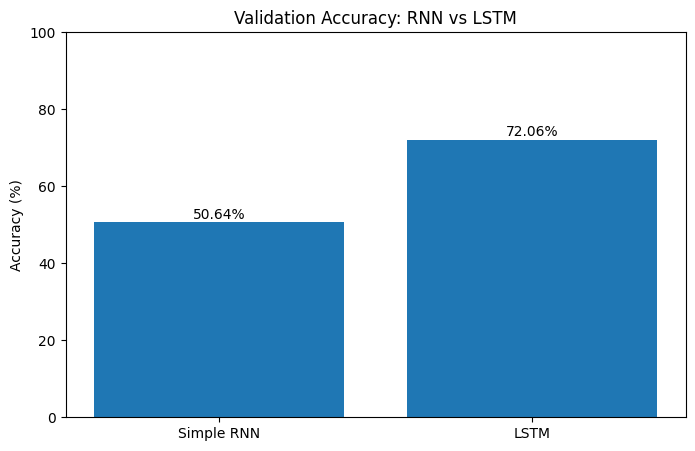

In [ ]:
plt.figure(figsize=(8, 5))

models = ["Simple RNN", "LSTM"]

accuracies = [
    rnn_history["val_accuracy"][-1] * 100,
    lstm_history["val_accuracy"][-1] * 100
]

plt.bar(models, accuracies)

plt.title("Validation Accuracy: RNN vs LSTM")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

In [ ]:
# Evaluate LSTM on the test dataset

lstm_test_metrics = evaluate_model(
    lstm_model,
    test_loader,
    lstm_criterion,
    device
)

print("LSTM Test Results")
print("-" * 40)

for metric, value in lstm_test_metrics.items():
    print(f"{metric.capitalize():15s}: {value:.4f}")

LSTM Test Results
----------------------------------------
Loss           : 0.6258
Accuracy       : 0.7056
Precision      : 0.7596
Recall         : 0.6016
F1             : 0.6714
Roc_auc        : 0.7392


              precision    recall  f1-score   support

    Negative       0.67      0.81      0.73      2500
    Positive       0.76      0.60      0.67      2500

    accuracy                           0.71      5000
   macro avg       0.71      0.71      0.70      5000
weighted avg       0.71      0.71      0.70      5000



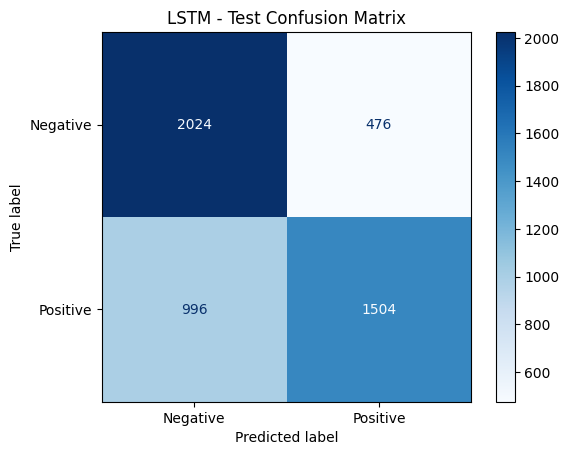

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

lstm_model.eval()

test_predictions = []
test_actuals = []
test_probabilities = []

with torch.no_grad():
    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        logits = lstm_model(inputs)
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).int()

        test_predictions.extend(predictions.cpu().numpy())
        test_actuals.extend(labels.numpy())
        test_probabilities.extend(probabilities.cpu().numpy())

print(classification_report(
    test_actuals,
    test_predictions,
    target_names=["Negative", "Positive"]
))

ConfusionMatrixDisplay.from_predictions(
    test_actuals,
    test_predictions,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("LSTM - Test Confusion Matrix")
plt.show()

In [ ]:
# Save LSTM model
LSTM_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "lstm_model.pth"
)

torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "max_length": MAX_LEN
}, LSTM_MODEL_PATH)

# Save training history and test metrics
experiment_data = {
    "model": "LSTM",
    "training_history": lstm_history,
    "test_metrics": lstm_test_metrics
}

with open(
    os.path.join(REPORT_DIR, "lstm_experiment.json"),
    "w"
) as f:
    json.dump(experiment_data, f, indent=4)

print("LSTM model and experiment results saved!")
print("Model:", LSTM_MODEL_PATH)

LSTM model and experiment results saved!
Model: /content/drive/MyDrive/SentimentForge/models/lstm_model.pth


In [ ]:
print("Model exists:", os.path.exists(LSTM_MODEL_PATH))

with open(os.path.join(REPORT_DIR, "lstm_experiment.json")) as f:
    saved_results = json.load(f)

print("Saved model:", saved_results["model"])
print("Saved test accuracy:",
      saved_results["test_metrics"]["accuracy"])

Model exists: True
Saved model: LSTM
Saved test accuracy: 0.7056
